In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

plt.style.use('seaborn-v0_8-darkgrid')
pd.set_option('display.max_columns', None)

In [ ]:
tickers = ["QQQ", "^VXN"]
data = yf.download(tickers, start="2021-01-01", end="2026-01-01")

qqq_close = data['Close']['QQQ']
vxn_close = data['Close']['^VXN']

raw_df = pd.DataFrame({'QQQ': qqq_close, 'VXN': vxn_close})

# Identify rows where at least one column has a missing value
missing_rows = raw_df[raw_df.isna().any(axis=1)]

print(f"Total rows downloaded: {len(raw_df)}")
print(f"Rows with missing data: {len(missing_rows)}")

/Users/ansonlai/Desktop/2026-27_Sem_1/STAT4601/Group Project/.conda/lib/python3.12/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/ansonlai/Desktop/2026-27_Sem_1/STAT4601/Group Project/.conda/lib/python3.12/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/Users/ansonlai/Desktop/2026-27_Sem_1/STAT4601/Group Project/.conda/lib/python3.12/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP

Total rows downloaded: 1255
Rows with missing data: 0



/Users/ansonlai/Desktop/2026-27_Sem_1/STAT4601/Group Project/.conda/lib/python3.12/site-packages/yfinance/multi.py:220: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.rename(columns=ctx.isins, inplace=True)
/Users/ansonlai/Desktop/2026-27_Sem_1/STAT4601/Group Project/.conda/lib/python3.12/site-packages/yfinance/multi.py:224: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.sort_index(level=0, axis=1, inplace=True)


In [ ]:
# Calculate QQQ Daily Log Returns
df['Log_Ret'] = np.log(df['QQQ'] / df['QQQ'].shift(1)) # Lost data of the 1st row. The log return on 4/1/2026 cannot be calculated as we don't have data on 3/1/2021

# Calculate 21-day Rolling Realized Volatility (RV)
# Multiply by 100 to convert the standard deviation to a percentage, so it is on the same scale as the VXN index
df['RV'] = df['Log_Ret'].rolling(window=21).std() * np.sqrt(252) * 100 
'''
The rolling window is set to 21 days. As calculating daily log returns requires the previous day's price (shift(1)), the first row of the dataset has a missing Log_Ret. 
Therefore, the RV calculation only begins on the 22nd row of the dataset, meaning the first 21 rows of the RV column will be missing.
'''
df['Spread'] = df['VXN'] - df['RV']

df = df.dropna()

In [ ]:
#Keep last 5 values for true test)
train_df = df.iloc[:-5].copy()
test_df = df.iloc[-5:].copy()

print(f"Training data size: {len(train_df)}")
print(f"Test data size: {len(test_df)}")
print("\nLast 5 true values (Holdout Set):")
print(test_df[['VXN', 'RV', 'Spread']])

Training data size: 1208
Test data size: 5

Last 5 true values (Holdout Set):
                  VXN         RV    Spread
Date                                      
2025-12-24  17.200001  13.469343  3.730657
2025-12-26  17.379999  13.371854  4.008145
2025-12-29  18.389999  13.232612  5.157388
2025-12-30  18.950001  12.977360  5.972641
2025-12-31  19.559999  13.251901  6.308099


In [ ]:
# Stationarity Check (ADF Test)
def run_adf_test(series):
    print("Augmented Dickey-Fuller Test")
    print("-" * 50)
    result = adfuller(series, autolag='AIC')

    adf_stat = result[0]
    p_value = result[1]
    critical_values = result[4]
    
    print(f"ADF Statistic: {adf_stat:.4f}")
    print(f"p-value: {p_value:.4f}")
    print("Critical Values:")
    for key, value in critical_values.items():
        print(f"   {key}: {value:.4f}")

    if p_value < 0.05:
        print("=> Reject the null hypothesis. The series is stationary.\n")
    else:
        print("=> Fail to reject the null hypothesis. The series is NON-stationary.\n")

run_adf_test(train_df['Spread'])

Augmented Dickey-Fuller Test
--------------------------------------------------
ADF Statistic: -4.2782
p-value: 0.0005
Critical Values:
   1%: -3.4359
   5%: -2.8640
   10%: -2.5681
=> Reject the null hypothesis. The series is stationary.



/var/folders/g6/jl_vfnld2l94j5m94f_kmxxw0000gn/T/ipykernel_20623/2978464641.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series, autolag='AIC')


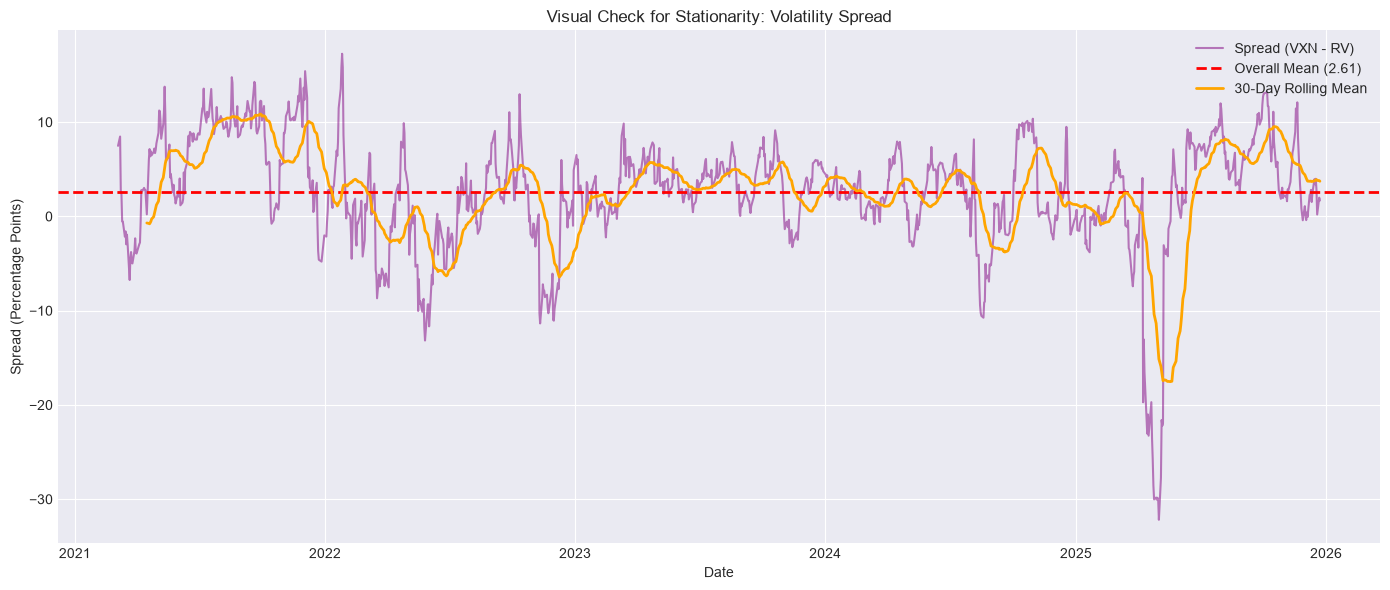

Conclusion for Phase 1:
1. The mean of the spread is roughly constant (around 2.61).
2. The ADF test p-value is < 0.05, confirming the series is stationary.
3. Therefore, the integration order d = 0. We will proceed to build an ARMA(p,q) model in Phase 2 without differencing.


In [ ]:
rolling_mean = train_df['Spread'].rolling(window=30).mean()
overall_mean = train_df['Spread'].mean()

plt.figure(figsize=(14, 6))

plt.plot(train_df.index, train_df['Spread'], color='purple', alpha=0.5, label='Spread (VXN - RV)')

plt.axhline(overall_mean, color='red', linestyle='--', linewidth=2, label=f'Overall Mean ({overall_mean:.2f})')
plt.plot(train_df.index, rolling_mean, color='orange', linewidth=2, label='30-Day Rolling Mean')

plt.title('Visual Check for Stationarity: Volatility Spread')
plt.xlabel('Date')
plt.ylabel('Spread (Percentage Points)')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

print("Conclusion for Phase 1:")
print(f"1. The mean of the spread is roughly constant (around {overall_mean:.2f}).")
print("2. The ADF test p-value is < 0.05, confirming the series is stationary.")
print("3. Therefore, the integration order d = 0.")

In [ ]:

train_df.to_csv('train_data_clean.csv')
test_df.to_csv('test_data_holdout.csv')
print("Data saved successfully!")

Data saved successfully!
